**Author:**

Kumar Jayant

# Don't Guess: Let Customer Behaviour Decide Your Segments — Notebook 2: Clustering customer data from a food and wine retailer

Companion notebook to the aimldl.io post (RFM series, Part 3: unsupervised clustering). Notebook 1 prepared the data; this notebook does the scaling, clustering and insights.

**Data:** [Customer Personality: Clean Data for Segmentation](https://www.kaggle.com/datasets/krjynt/customer-personality-clean-data-for-segmentation) (CC0: Public Domain), the cleaned output of Notebook 1. It has 2,240 customers of a food and wine retailer, one row each, with no missing values. There are 28 columns: 17 numeric (income, age, tenure, recency, spend on six product groups, purchases by channel, deals, web visits, children at home) and 9 categorical (education, marital status, five past campaign responses, the latest campaign response, complaints). The source is [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis) by imakash3011. The data is used as an illustration of the approach, not as evidence.

**Method Used:** the data mixes numbers and categories. k-means works only on numbers, and k-modes only on categories. **k-prototypes** handles both in one model, so who customers are and what they do can go in together.

**What this notebook does**
1. **Settings:** one cell lists the ID column, the numeric columns and the categorical columns. Change only this cell to run the notebook on your own data.
2. **Checks the input:** stops with a plain-language message if a listed column is missing or has blanks.
3. **Scales the numeric columns** (standard scaling, so income in thousands doesn't drown out visits in single digits). Categorical columns are left as they are.
4. **Chooses the number of clusters:** compares a range of k on the model's cost, then picks the number that is both statistically reasonable and something a business team can act on.
5. **Runs k-prototypes** with the chosen k and a fixed random seed, so the results can be repeated.
6. **Profiles each cluster:** size, average spend, channel mix, campaign response, and its most common education, marital status and household type.
7. **Names the clusters** in business language and suggests what each one would call for.
8. **Exports** each customer's cluster label (`cluster_labels.csv`) and the cluster profile table (`cluster_profiles.csv`).

**Using your own data:** one row per customer, no missing values, numeric and categorical columns of any mix. Fill in the settings cell and run all.

In [2]:
!pip install kmodes

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import KBinsDiscretizer
import glob, os
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import FancyBboxPatch
import matplotlib.ticker as mticker
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from kmodes.kprototypes import KPrototypes
import matplotlib.pyplot as plt


pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Import the dataset

In [17]:
## 1. Import the dataset
# Data: pulled straight from Kaggle (works in Colab and in Kaggle notebooks; cached after the first download).
# To run on your own file instead, comment out the next two lines and set DATA_PATH to your CSV, e.g.
# DATA_PATH = '/content/my_customers.csv'

path = kagglehub.dataset_download('krjynt/customer-personality-clean-data-for-segmentation')
DATA_PATH = glob.glob(os.path.join(path, '*.csv'))[0]
print(DATA_PATH)

Using Colab cache for faster access to the 'customer-personality-clean-data-for-segmentation' dataset.
/kaggle/input/customer-personality-clean-data-for-segmentation/customer_personality_clean.csv


In [18]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
# should be (2240, 28)

(2240, 28)


## 2. Settings

In [20]:
## 2. Settings: the only cell to change for your own data

ID_COL = 'ID'

NUMERIC_COLS = [
    'Income', 'Age', 'Tenure_months', 'Kidhome', 'Teenhome', 'Recency',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
    'MntSweetProducts', 'MntGoldProds',
    'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
    'NumStorePurchases', 'NumWebVisitsMonth',
]

CATEGORICAL_COLS = [
    'Education', 'Marital_Status',
    'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5',
    'Response', 'Complain',
]

# Optional: totals to show in the profile, since the dataset doesn't have total spend only by category spend

DERIVED_SUMS = {
    'Total_spend':     ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
                        'MntSweetProducts', 'MntGoldProds'],
    'Total_purchases': ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases'],
    'Children':        ['Kidhome', 'Teenhome'],
}

K_RANGE = range(2, 11)   # numbers of clusters to compare
RANDOM_STATE = 42        # fixed seed so results repeat

In [21]:
## 3. Check the input

problems = []

# 1. Every listed column must exist
listed = [ID_COL] + NUMERIC_COLS + CATEGORICAL_COLS
missing_cols = [c for c in listed if c not in df.columns]
if missing_cols:
    problems.append(f"These columns are in the settings but not in your file: {missing_cols}")

else:
    # 2. No column listed twice
    overlap = set(NUMERIC_COLS) & set(CATEGORICAL_COLS)
    if overlap:
        problems.append(f"These columns are listed as both numeric and categorical: {sorted(overlap)}")

    # 3. No blanks in the listed columns
    blanks = df[listed].isna().sum()
    blanks = blanks[blanks > 0]
    if not blanks.empty:
        problems.append(f"These columns have blank values (fill or drop them first): {blanks.to_dict()}")

    # 4. Numeric columns must hold numbers
    non_numeric = [c for c in NUMERIC_COLS if not pd.api.types.is_numeric_dtype(df[c])]
    if non_numeric:
        problems.append(f"These numeric columns contain text: {non_numeric}")

    # 5. One row per customer
    dupes = df[ID_COL].duplicated().sum()
    if dupes:
        problems.append(f"{dupes} customer IDs appear more than once; keep one row per customer.")

if problems:
    raise ValueError("Input check failed:\n- " + "\n- ".join(problems))

print(f"Input check passed: {len(df):,} customers, "
      f"{len(NUMERIC_COLS)} numeric and {len(CATEGORICAL_COLS)} categorical columns.")

Input check passed: 2,240 customers, 17 numeric and 9 categorical columns.


## 3. Prepare the data for Kprototypes modelling

In [22]:
## 4. Prepare the data for the model

# Numeric: standard scaling (mean 0, spread 1), so no column dominates just because of its units
scaler = StandardScaler()
num_scaled = pd.DataFrame(
    scaler.fit_transform(df[NUMERIC_COLS]),
    columns=NUMERIC_COLS, index=df.index
)

# Categorical: stored as text, so 0/1 flags are read as categories, not numbers
cat_text = df[CATEGORICAL_COLS].astype(str)

# One model-ready table: numeric first, then categorical
X_df = pd.concat([num_scaled, cat_text], axis=1)
X = X_df.to_numpy(dtype=object)

# Positions of the categorical columns, which k-prototypes needs
CAT_IDX = list(range(len(NUMERIC_COLS), X.shape[1]))

print(X.shape)                                   # expect (2240, 26)
print(num_scaled.describe().loc[['mean', 'std']].round(2))   # means ~0, std ~1

(2240, 26)
      Income   Age  Tenure_months  Kidhome  Teenhome  Recency  MntWines  \
mean    0.00 -0.00          -0.00    -0.00     -0.00    -0.00     -0.00   
std     1.00  1.00           1.00     1.00      1.00     1.00      1.00   

      MntFruits  MntMeatProducts  MntFishProducts  MntSweetProducts  \
mean      -0.00             0.00             0.00             -0.00   
std        1.00             1.00             1.00              1.00   

      MntGoldProds  NumDealsPurchases  NumWebPurchases  NumCatalogPurchases  \
mean         -0.00              -0.00            -0.00                 0.00   
std           1.00               1.00             1.00                 1.00   

      NumStorePurchases  NumWebVisitsMonth  
mean               0.00              -0.00  
std                1.00               1.00  


## 3. Modelling starts here

k=2: cost 28,745, smallest cluster 41.5%
k=3: cost 25,420, smallest cluster 26.7%
k=4: cost 23,988, smallest cluster 23.9%
k=5: cost 22,976, smallest cluster 9.2%
k=6: cost 22,018, smallest cluster 8.8%
k=7: cost 21,347, smallest cluster 8.5%
k=8: cost 20,775, smallest cluster 7.5%
k=9: cost 20,358, smallest cluster 7.5%
k=10: cost 19,846, smallest cluster 0.2%


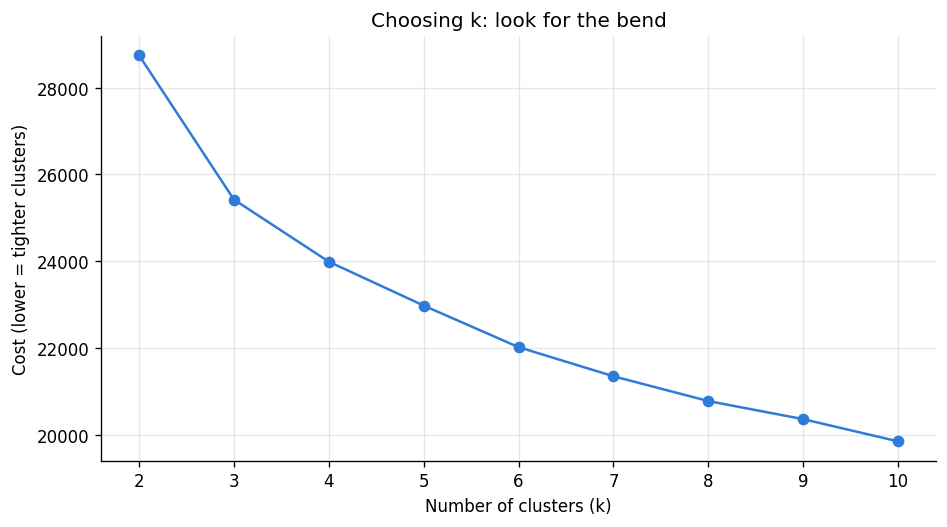

,k,cost,smallest_cluster_%
0,2,"28,744.61",41.50
1,3,"25,419.68",26.70
2,4,"23,987.84",23.90
3,5,"22,976.02",9.20
4,6,"22,017.99",8.80
5,7,"21,347.10",8.50
6,8,"20,775.10",7.50
7,9,"20,358.32",7.50
8,10,"19,846.23",0.20


In [24]:
## 5. Choose the number of clusters

results = []
for k in K_RANGE:
    kp = KPrototypes(n_clusters=k, init='Cao', n_init=5,
                     random_state=RANDOM_STATE, n_jobs=-1)
    labels = kp.fit_predict(X, categorical=CAT_IDX)
    sizes = pd.Series(labels).value_counts()
    results.append({
        'k': k,
        'cost': kp.cost_,
        'smallest_cluster_%': round(100 * sizes.min() / len(labels), 1),
    })
    print(f"k={k}: cost {kp.cost_:,.0f}, smallest cluster {100 * sizes.min() / len(labels):.1f}%")

k_table = pd.DataFrame(results)

# Elbow chart: where the cost stops falling sharply
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_table['k'], k_table['cost'], marker='o', color='#2f7bd9')
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Cost (lower = tighter clusters)')
ax.set_title('Choosing k: look for the bend')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

k_table

In [25]:
## 6. Fit the final model

K_FINAL = 4   # set from the elbow chart and the business test above

kp_final = KPrototypes(n_clusters=K_FINAL, init='Cao', n_init=10,
                       random_state=RANDOM_STATE, n_jobs=-1)
labels = kp_final.fit_predict(X, categorical=CAT_IDX)

# Attach labels to the original (unscaled) data, numbered from 1 for readability
df['Cluster'] = labels + 1

sizes = df['Cluster'].value_counts().sort_index()
print(f"Gamma (numeric vs categorical weight): {kp_final.gamma:.2f}")
print(pd.DataFrame({'customers': sizes,
                    'share_%': (100 * sizes / len(df)).round(1)}))

Gamma (numeric vs categorical weight): 0.50
         customers  share_%
Cluster                    
1              542    24.20
2              583    26.00
3              579    25.80
4              536    23.90


In [26]:
## 7. Profile the clusters

# --- Optional totals from the settings ---
for name, cols in DERIVED_SUMS.items():
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f"DERIVED_SUMS['{name}'] uses columns not in your file: {missing}")
    df[name] = df[cols].sum(axis=1)
DERIVED_COLS = list(DERIVED_SUMS)

# --- Size ---
size = df['Cluster'].value_counts().sort_index()
size_tbl = pd.DataFrame({'Customers': size,
                         'Share of customers (%)': (100 * size / len(df)).round(1)})

# --- Numeric: average per cluster, in real units ---
num_cols_all = DERIVED_COLS + NUMERIC_COLS
num_mean = df.groupby('Cluster')[num_cols_all].mean().round(1)

# Index vs the average customer (100 = average; 150 = 50% above average)
overall = df[num_cols_all].mean().replace(0, np.nan)
num_index = (100 * num_mean / overall).round(0)

# --- Categorical: yes/no flags as % yes; other categories as top value and its share ---
binary_cols = [c for c in CATEGORICAL_COLS
               if set(df[c].astype(str).unique()) <= {'0', '1'}]
other_cats = [c for c in CATEGORICAL_COLS if c not in binary_cols]

yes_rate = ((df[binary_cols].astype(str) == '1')
            .groupby(df['Cluster']).mean() * 100).round(1)
yes_rate.columns = [f"{c} (% yes)" for c in binary_cols]

def top_value(s):
    vc = s.value_counts(normalize=True)
    return f"{vc.index[0]} ({100 * vc.iloc[0]:.0f}%)"

top_cats = df.groupby('Cluster')[other_cats].agg(top_value)
top_cats.columns = [f"{c} (most common)" for c in other_cats]

# --- One profile table: clusters as columns, measures as rows ---
cluster_profile = pd.concat([size_tbl, num_mean, yes_rate, top_cats], axis=1).T
cluster_profile.columns = [f"Cluster {c}" for c in cluster_profile.columns]
display(cluster_profile)

,Cluster 1,Cluster 2,Cluster 3,Cluster 4
Customers,542,583,579,536
Share of customers (%),24.20,26.00,25.80,23.90
Total_spend,808.90,"1,359.10",102.50,124.70
Total_purchases,17.90,19.60,5.90,6.60
Children,1.10,0.20,0.80,1.70
Income,"58,921.70","75,633.90","29,590.10","43,419.20"
Age,49.20,45.60,36.00,50.20
Tenure_months,13.90,11.60,11.30,9.70
Kidhome,0.20,0.00,0.80,0.70
Teenhome,0.90,0.20,0.00,1.00


In [27]:
# --- Where each cluster stands out: index heatmap ---
display(num_index.T.style
        .background_gradient(cmap='RdYlGn', vmin=50, vmax=150, axis=None)
        .format('{:.0f}')
        .set_caption('Index vs average customer (100 = average)'))

# --- Full mix for the non-flag categories ---
for c in other_cats:
    mix = (pd.crosstab(df['Cluster'], df[c], normalize='index') * 100).round(1)
    display(mix.style.background_gradient(cmap='Blues', axis=1)
            .format('{:.1f}%').set_caption(f'{c} mix by cluster (%)'))

Cluster,1,2,3,4
Total_spend,134,224,17,21
Total_purchases,143,156,47,53
Children,116,21,84,179
Income,113,146,57,84
Age,109,101,80,111
Tenure_months,120,100,97,83
Kidhome,45,0,180,158
Teenhome,178,40,0,198
Recency,98,101,99,102
MntWines,171,193,11,23


Education,Basic,Graduation,Master,PhD
Cluster,,,,
1,0.2%,47.8%,23.2%,28.8%
2,0.2%,55.7%,23.8%,20.2%
3,7.9%,50.6%,27.5%,14.0%
4,1.1%,46.6%,27.8%,24.4%


Marital_Status,Divorced,Married,Single,Together,Widow
Cluster,,,,,
1,12.4%,41.3%,16.6%,24.9%,4.8%
2,9.4%,35.8%,24.7%,25.7%,4.3%
3,8.3%,40.2%,26.3%,24.4%,0.9%
4,11.6%,37.7%,18.1%,28.7%,3.9%


**How to read this chart**
Each cell compares a cluster's average with the average customer. 100 means the same as the average; 200 means twice the average; 50 means half. Green is well above average, red well below and yellow close to it. Read down a column to see what defines a cluster, and across a row to see which cluster leads on that measure. Green means "more", not "better": a green cell for children simply means more children at home.

**What it shows**
- **Cluster 2 is green almost everywhere it spends:** 224 on total spend and about 265–270 on fruit, meat, fish and sweets, with catalogue purchases at 225. It is red on deals (56), web visits (53) and children (21). These are big, full-price, child-free baskets.
- **Cluster 1 is a wine and deals story:** wine 171, gold 149, deals 163, web purchases 162 and teenagers at home 178. Its spend on fruit, meat, fish and sweets sits slightly below average (84–88).
- **Cluster 3 is red on almost every spend row** (11–25) and on income (57) and age (80). It is green on young children (180) and web visits (130). Its customers browse a lot, buy little and have small children.
- **Cluster 4 is also red on spend** (15–32). It has the most children (179 overall: teens 198, young kids 158), is the newest group (tenure 83) and is the oldest (age 111).
- **Recency is yellow across the board** (98–102). Every cluster last bought about equally recently.

**The takeaway**
Behaviour separates these customers far more than demographics do. Spend, channel and deal use split the clusters sharply, while age and education barely move. Recency, a pillar of RFM, doesn't separate them at all. Rules built on recency alone would have missed all four groups.

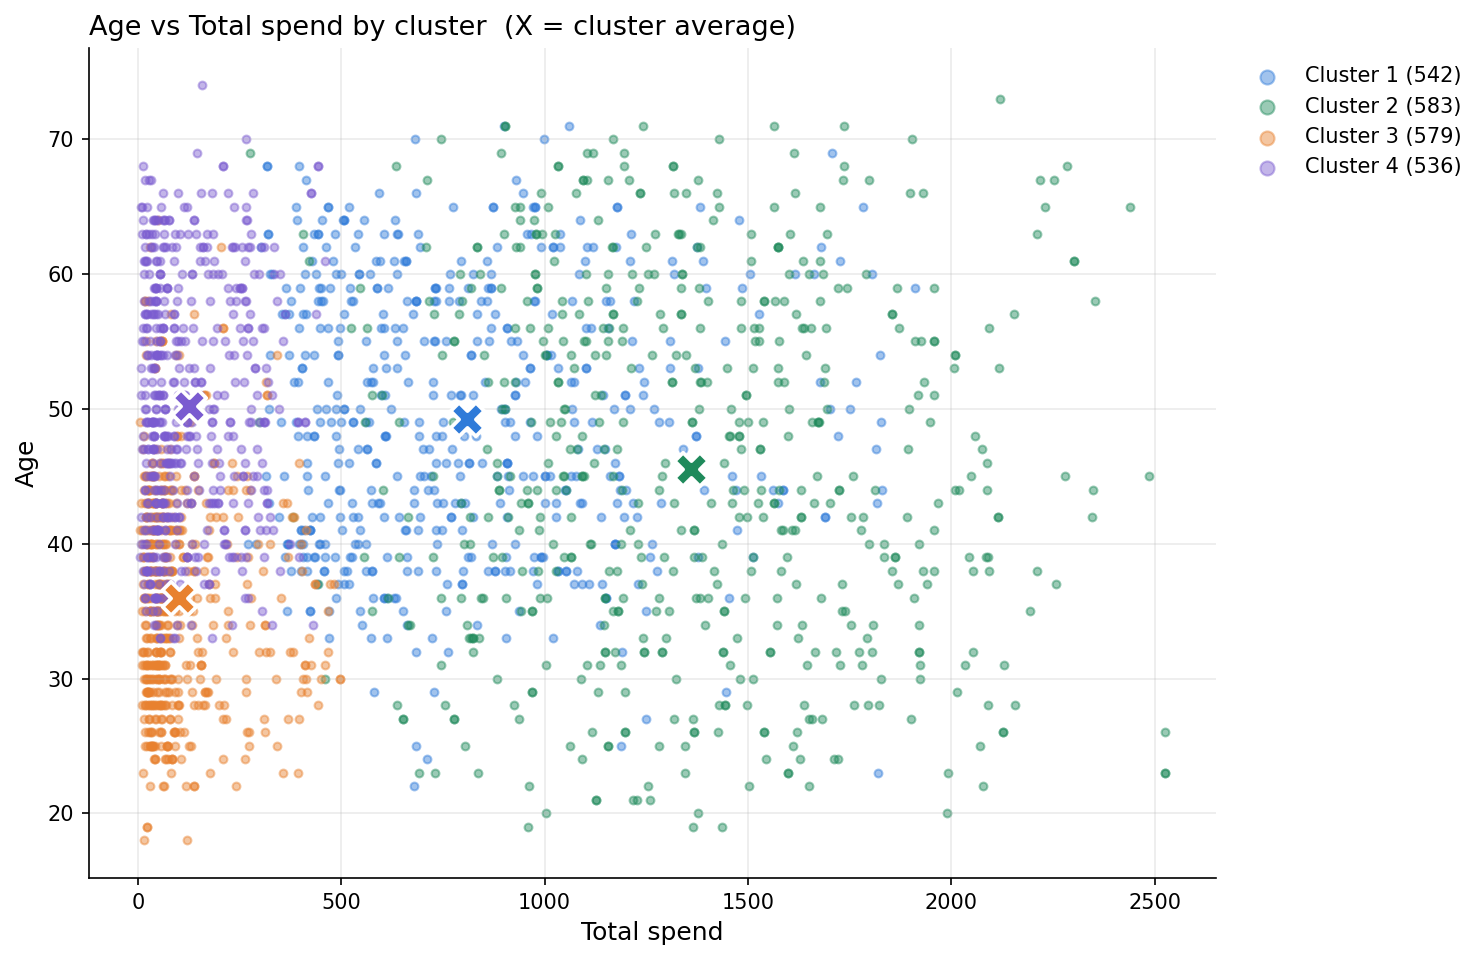

In [28]:
## 8. Scatter: spend vs age by cluster

X_AXIS = 'Total_spend'   # from DERIVED_SUMS; any numeric column works
Y_AXIS = 'Age'

for c in (X_AXIS, Y_AXIS):
    if c not in df.columns:
        raise ValueError(f"'{c}' is not a column in the data. Check X_AXIS / Y_AXIS.")

palette = ['#2f7bd9', '#1f8a5b', '#e8812f', '#7a5bd0',
           '#d94f4f', '#3fb6c4', '#b8860b', '#6b6b6b']   # enough for 8 clusters
clusters = sorted(df['Cluster'].unique())

fig, ax = plt.subplots(figsize=(10, 6.5), dpi=150)

for i, cl in enumerate(clusters):
    part = df[df['Cluster'] == cl]
    colour = palette[i % len(palette)]
    ax.scatter(part[X_AXIS], part[Y_AXIS], s=14, alpha=0.45, color=colour,
               label=f'Cluster {cl} ({len(part):,})')
    # Cluster centre: average spend and age
    ax.scatter(part[X_AXIS].mean(), part[Y_AXIS].mean(), s=260, marker='X',
               color=colour, edgecolor='white', linewidth=1.8, zorder=5)

ax.set_xlabel(X_AXIS.replace('_', ' '), fontsize=12)
ax.set_ylabel(Y_AXIS.replace('_', ' '), fontsize=12)
ax.set_title(f'{Y_AXIS.replace("_", " ")} vs {X_AXIS.replace("_", " ")} by cluster  (X = cluster average)',
             fontsize=13, loc='left')
ax.grid(alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=10, markerscale=1.8,
          loc='upper left', bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.savefig('scatter_spend_age.png', dpi=200, bbox_inches='tight')
plt.show()

**How to read this chart**
Each dot is a customer, placed by total spend over two years (left to right) and age (bottom to top), and coloured by cluster. The large X marks each cluster's average. Clusters were formed on all 26 columns, not just these two, so some overlap is expected: the chart shows a two-column slice of a much richer picture.

**What it shows**
- **Spend splits the clusters left to right.** Clusters 3 and 4 are bunched on the left, mostly under 300. Cluster 1 sits in the middle, around 400–1,300. Cluster 2 stretches furthest right, out to 2,500.
- **Among low spenders, age is what separates them.** Cluster 3 sits low (average age 36, most of them under 45), while Cluster 4 sits higher (average age 50). Same thin wallet share, different life stage: young children at home for one, teenagers for the other.
- **Among high spenders, age hardly matters.** Cluster 2 spans almost every age, from the early 20s to the 70s. What unites them is how much and how broadly they buy, not how old they are.
- **Clusters 1 and 2 overlap between about 700 and 1,400.** The model separated them on things this chart can't show: what they buy (wine-led vs. a full basket), how they buy (web and deals vs. catalogue and full price) and children at home.

**The takeaway**
Age by itself would be a poor way to segment these customers. Big spenders come in every age, so an age-based campaign would miss many of them. Age becomes useful only alongside behaviour, to split the low spenders into two groups that need different plays. Let behaviour lead, and let who they are refine it.

In [29]:
## 9. Export: each customer's cluster

# One row per customer: ID + cluster number and other original columns
cluster_labels = df[[ID_COL, 'Cluster'] + NUMERIC_COLS + CATEGORICAL_COLS + DERIVED_COLS]
cluster_labels.head()

,ID,Cluster,Income,Age,Tenure_months,Kidhome,Teenhome,Recency,MntWines,MntFruits,...,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response,Complain,Total_spend,Total_purchases,Children
0,5524,2,"58,138.00",57,22,0,0,58,635,88,...,0,0,0,0,0,1,0,1617,22,0
1,2174,4,"46,344.00",60,4,1,1,38,11,1,...,0,0,0,0,0,0,0,27,4,2
2,4141,2,"71,613.00",49,10,0,0,26,426,49,...,0,0,0,0,0,0,0,776,20,0
3,6182,3,"26,646.00",30,5,1,0,26,11,4,...,0,0,0,0,0,0,0,53,6,1
4,5324,3,"58,293.00",33,5,1,0,94,173,43,...,0,0,0,0,0,0,0,422,14,1


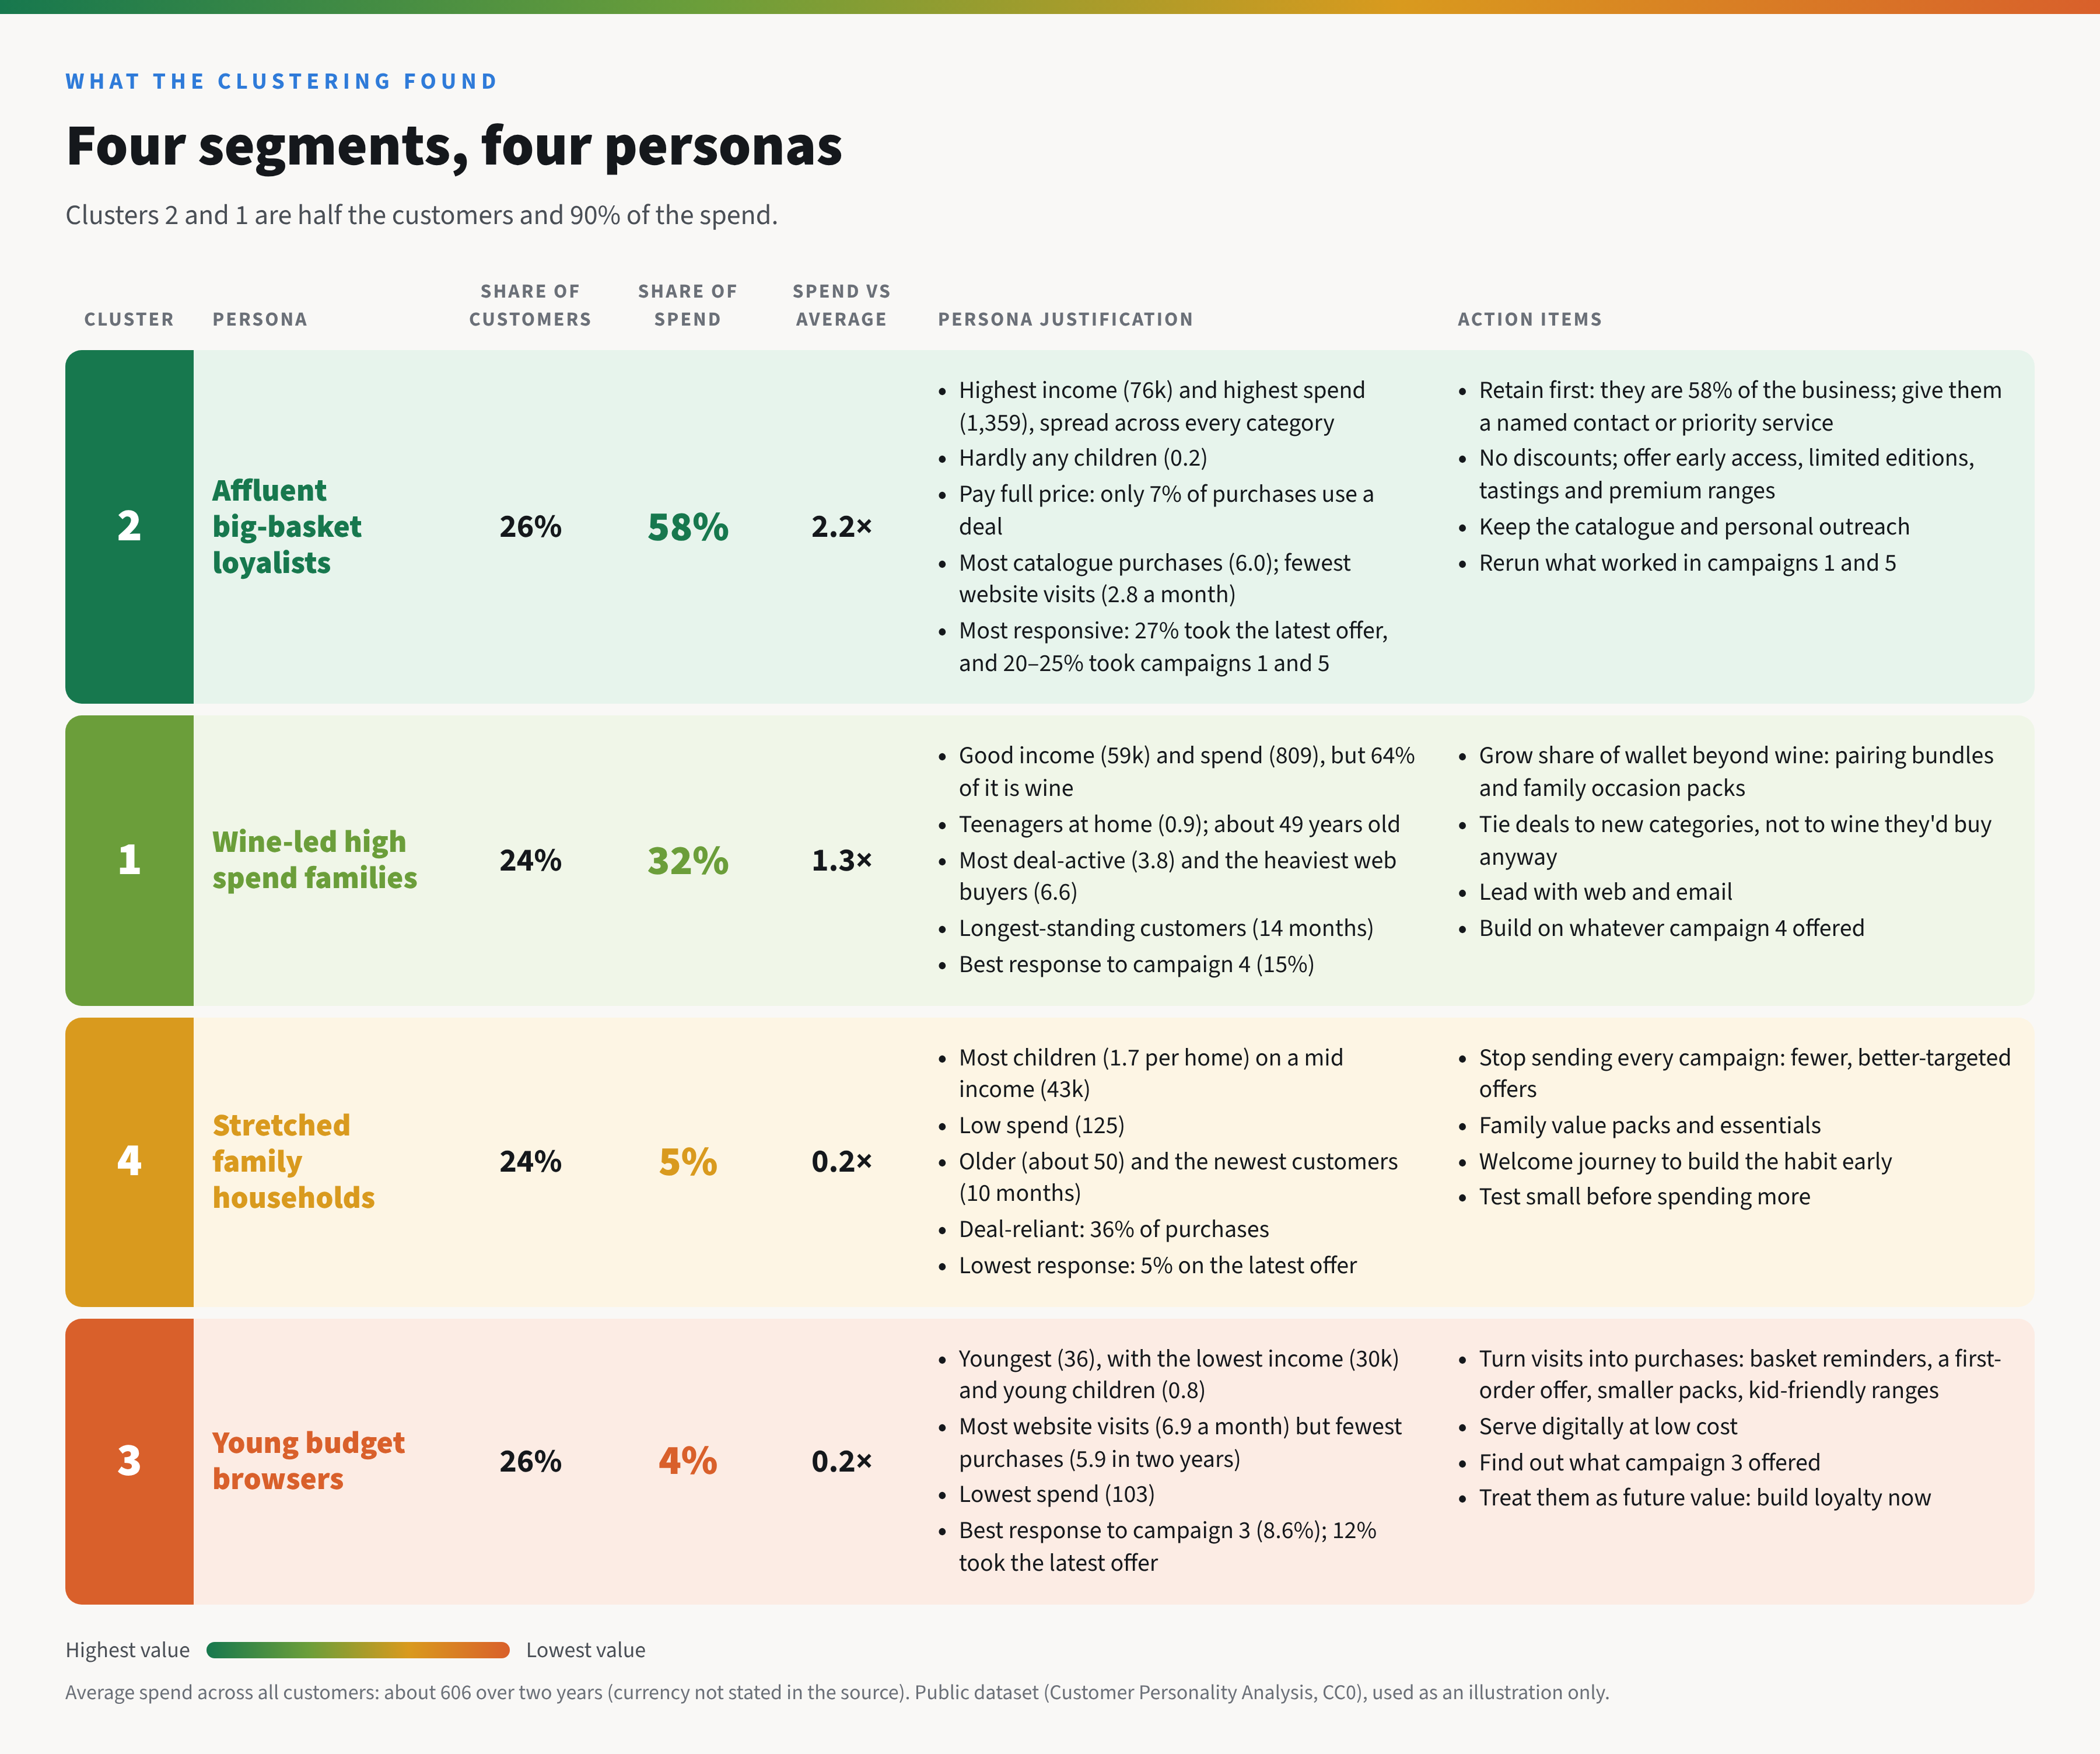

In [30]:
cluster_labels.to_csv('customer_clustered_segments.csv', index=False)

### End of code